 # Task 1 - Exploratory Data Analysis

In [1]:
 # %% Imports
import matplotlib.pyplot as plt
import importlib
import utils
from utils import DataLoader
# Reload the latest version of utils.py
importlib.reload(utils)
import pandas as pd
import numpy as np

# %% Load data
loader = utils.DataLoader()
loader.load_dataset()
data = loader.data
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## Data Quality and Descriptive Results

In [2]:
# Rows and Columns
data.shape

(5110, 12)

In [3]:
# Duplicate records or IDs
print("Number of duplicate IDs:", data["id"].duplicated().sum())

Number of duplicate IDs: 0


In [4]:
# Missing values by variables
missing_values = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage (%)": (data.isnull().sum() / len(data) * 100).round(2)
})

print(missing_values)

                   Missing Count  Missing Percentage (%)
id                             0                    0.00
gender                         0                    0.00
age                            0                    0.00
hypertension                   0                    0.00
heart_disease                  0                    0.00
ever_married                   0                    0.00
work_type                      0                    0.00
Residence_type                 0                    0.00
avg_glucose_level              0                    0.00
bmi                          201                    3.93
smoking_status                 0                    0.00
stroke                         0                    0.00


In [5]:
# Smoking Status - Unknown
unknown_count = (data["smoking_status"] == "Unknown").sum()
unknown_percentage = (unknown_count / len(data)) * 100

print(f"Unknown Smoking Count: {unknown_count}")
print(f"Unknown Smoking Percentage: {unknown_percentage:.2f}%")

Unknown Smoking Count: 1544
Unknown Smoking Percentage: 30.22%


In [6]:
# Stroke Class Count
stroke_counts = data["stroke"].value_counts().sort_index()
stroke_percentage = (data["stroke"].value_counts(normalize=True).sort_index() * 100).round(2)

stroke_summary = pd.DataFrame({
    "Count": stroke_counts,
    "Percentage (%)": stroke_percentage
})

print(stroke_summary)

        Count  Percentage (%)
stroke                       
0        4861           95.13
1         249            4.87


In [7]:
# Mean ± SD and Median (IQR) for age, avg_glucose_level, and bmi
variables = ["age", "avg_glucose_level", "bmi"]

summary = pd.DataFrame({
    "Mean ± SD": [
        f"{data[col].mean():.2f} ± {data[col].std():.2f}"
        for col in variables
    ],
    "Median (IQR)": [
        f"{data[col].median():.2f} ({data[col].quantile(0.25):.2f}–{data[col].quantile(0.75):.2f})"
        for col in variables
    ]
}, index=variables)

print(summary)

                        Mean ± SD          Median (IQR)
age                 43.23 ± 22.61   45.00 (25.00–61.00)
avg_glucose_level  106.15 ± 45.28  91.88 (77.25–114.09)
bmi                  28.89 ± 7.85   28.10 (23.50–33.10)


In [8]:
variables = ["age", "avg_glucose_level", "bmi"]

# Calculate minimum and maximum values
min_max_summary = data[variables].agg(["min", "max"]).T

min_max_summary.columns = ["Minimum", "Maximum"]

print(min_max_summary)

                   Minimum  Maximum
age                   0.08    82.00
avg_glucose_level    55.12   271.74
bmi                  10.30    97.60


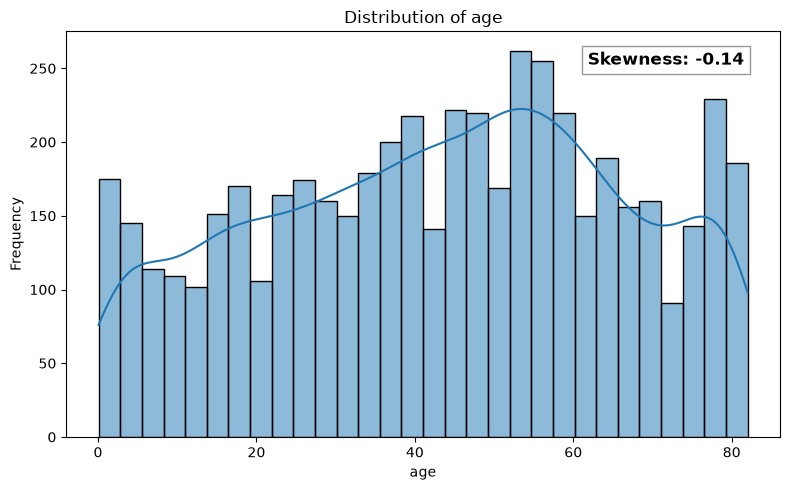

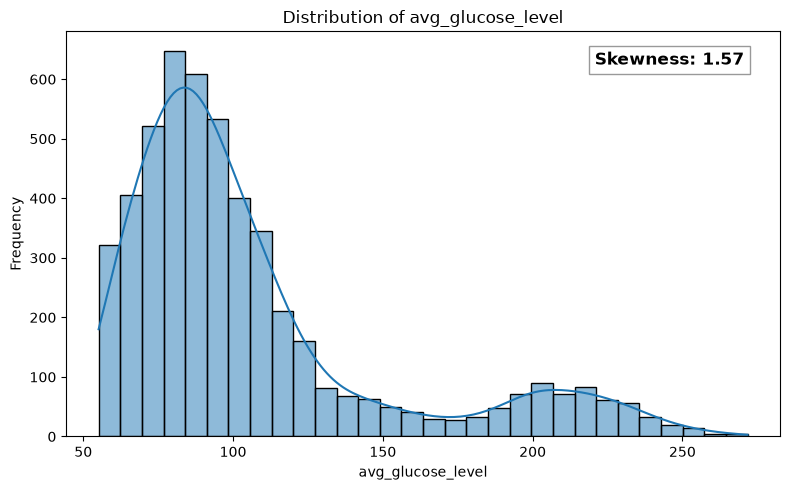

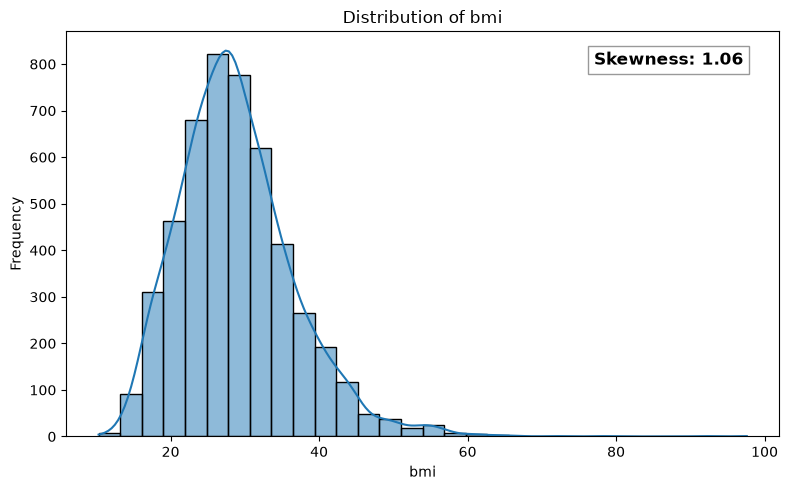

In [9]:
# Distribution of age, avg_glucose_level and bmi
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ["age", "avg_glucose_level", "bmi"]

for col in numerical_cols:
    plt.figure(figsize=(8, 5))

    sns.histplot(data[col].dropna(), bins=30, kde=True)

    # Calculate skewness
    skewness = data[col].skew()

    # Add skewness text inside the graph
    plt.text(
        0.95, 0.95,
        f"Skewness: {skewness:.2f}",
        transform=plt.gca().transAxes,
        fontsize=12,
        fontweight="bold",
        ha="right",
        va="top",
        bbox=dict(facecolor="white", edgecolor="gray", alpha=0.8)
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

In [10]:
# Distribution for Missingness
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy for missingness analysis
eda_data = data.copy()

# Treat "Unknown" smoking status as an unknown/missing value
eda_data["smoking_status"] = eda_data["smoking_status"].replace("Unknown", pd.NA)

# Missingness summary
missing_summary = pd.DataFrame({
    "Missing Count": eda_data.isnull().sum(),
    "Missing Percentage (%)": (
        eda_data.isnull().sum() / len(eda_data) * 100
    ).round(2)
})

missing_summary

,Missing Count,Missing Percentage (%)
id,0,0.00
gender,0,0.00
age,0,0.00
hypertension,0,0.00
heart_disease,0,0.00
ever_married,0,0.00
work_type,0,0.00
Residence_type,0,0.00
avg_glucose_level,0,0.00
bmi,201,3.93


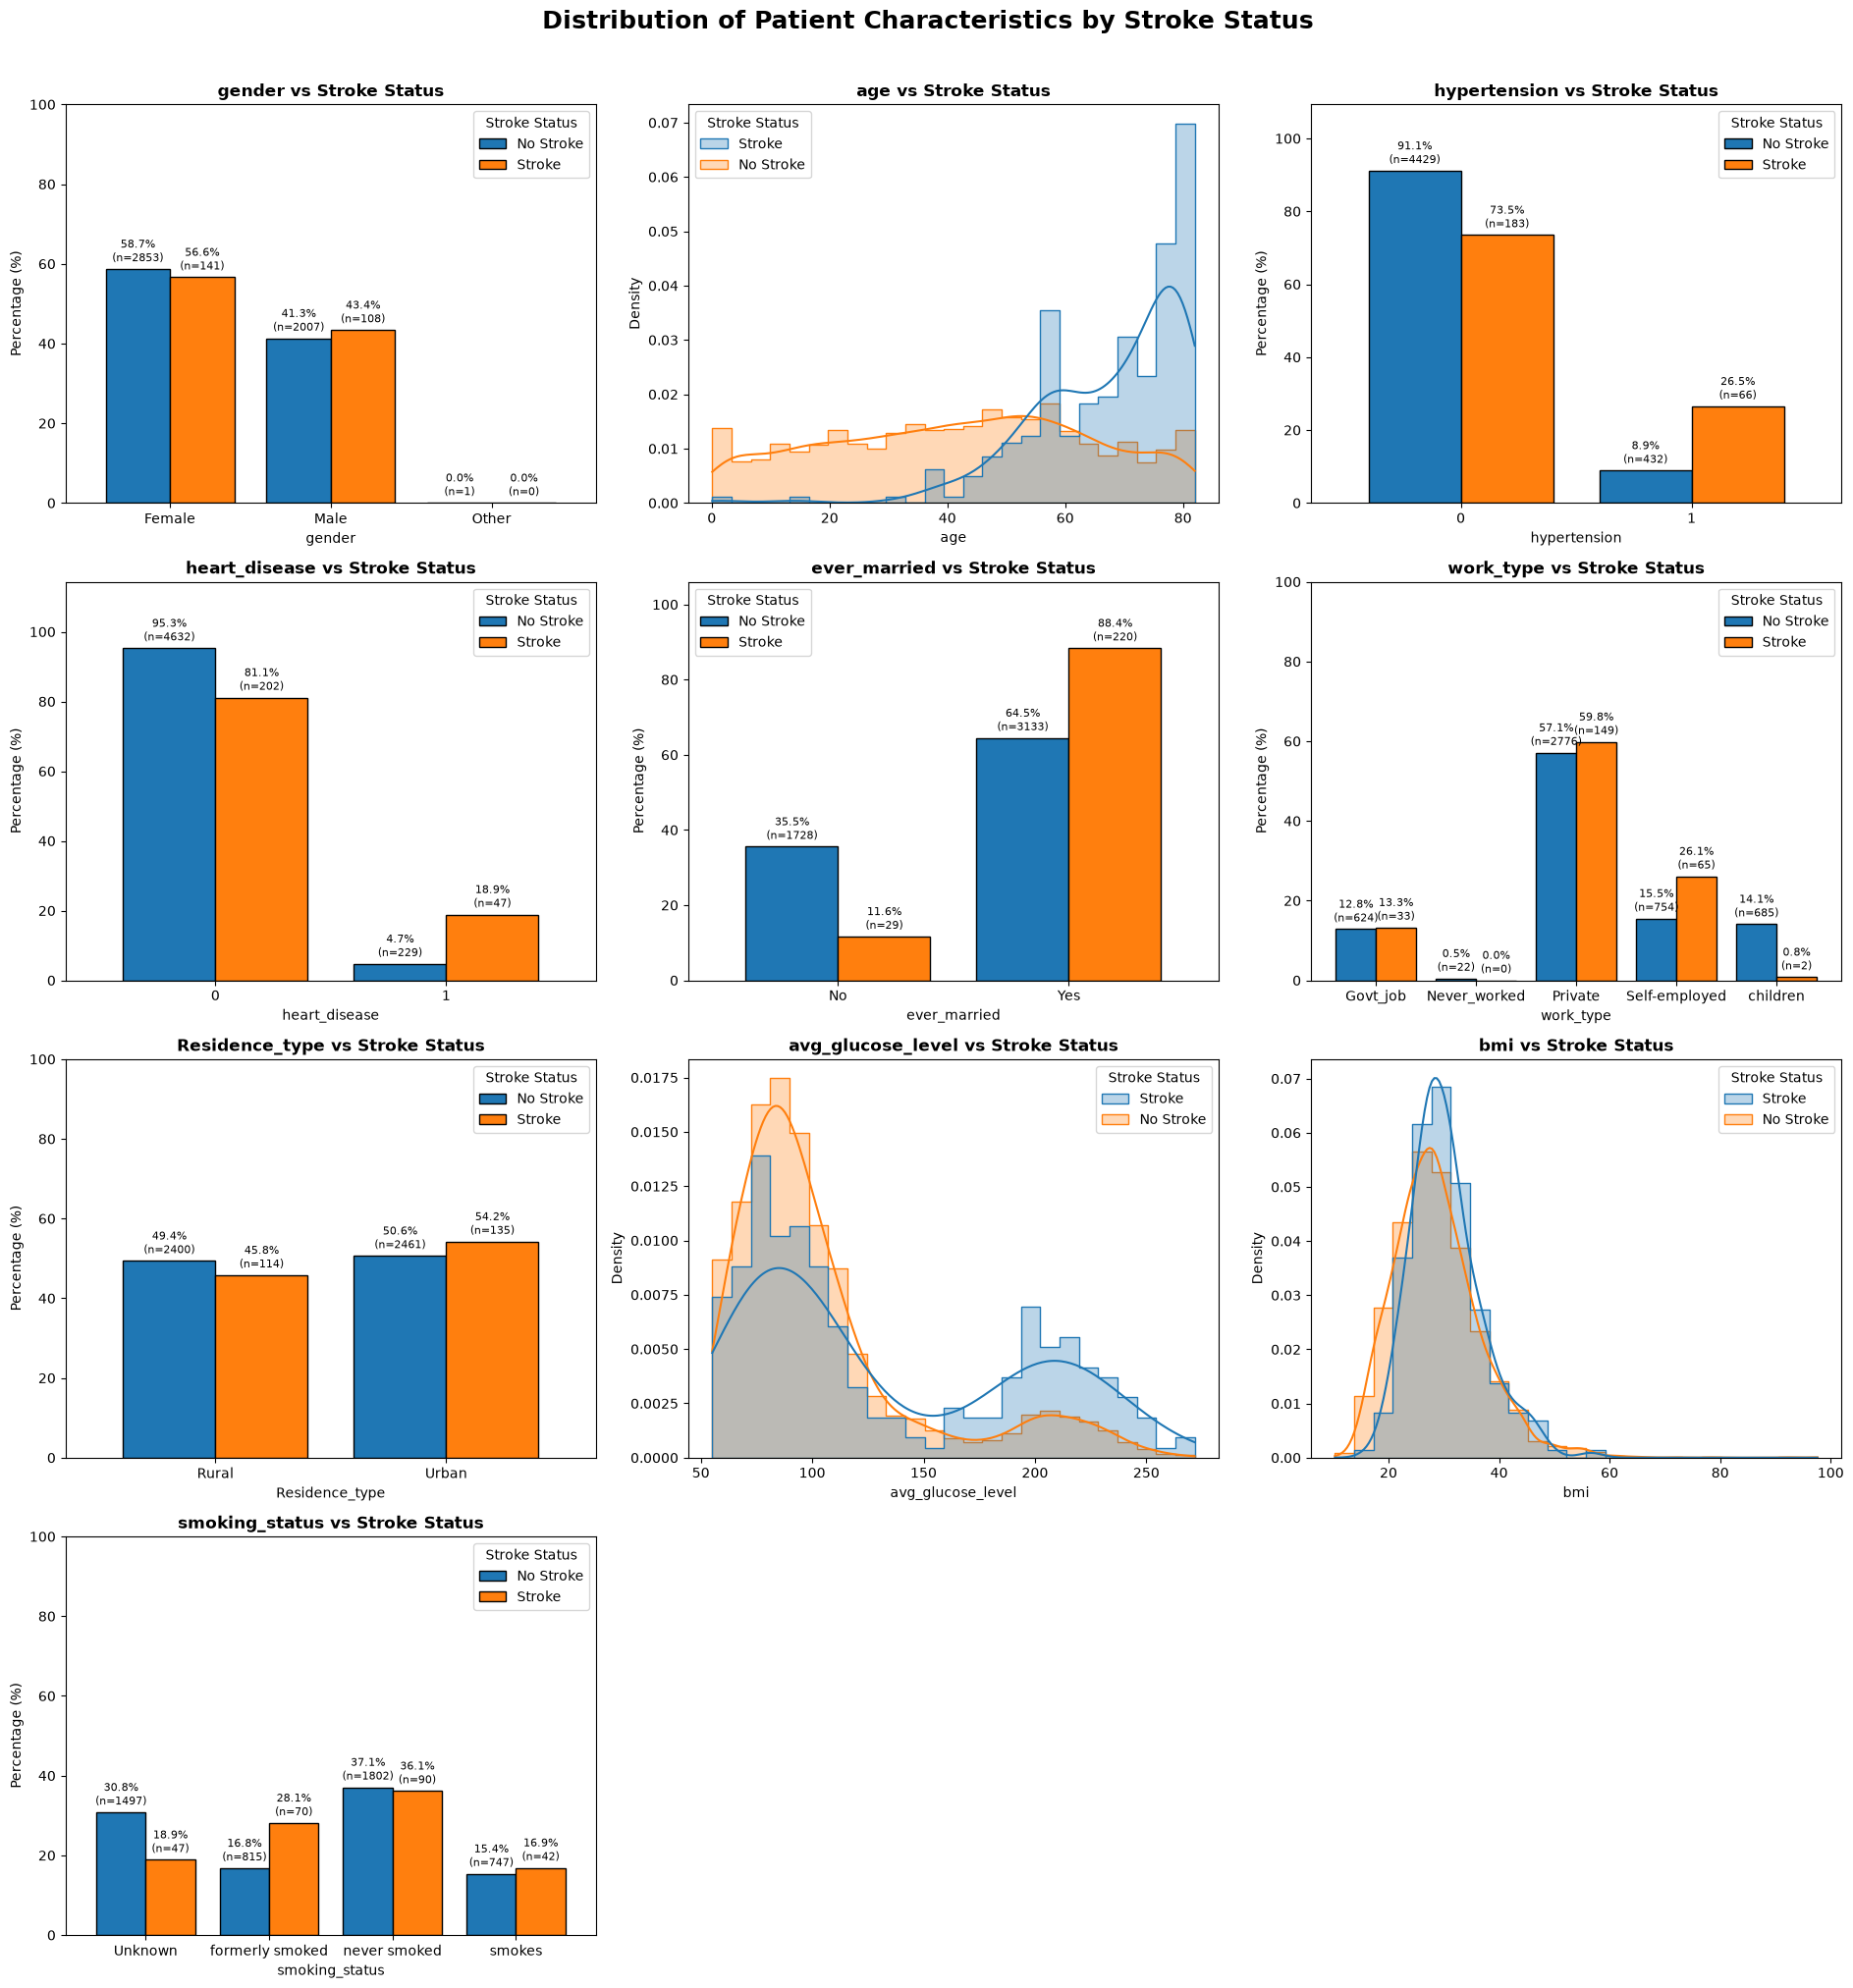

In [11]:
# All Columns by Stroke
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

# Define stroke labels
stroke_labels = {
    0: "No Stroke",
    1: "Stroke"
}

# Exclude ID and target column
columns = data.drop(
    columns=["id", "stroke"], errors="ignore"
).columns

# Create subplot layout
n_cols = 3
n_rows = math.ceil(len(columns) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(19, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(columns):

    ax = axes[i]

    # Numerical variables with more than 10 unique values
    if (
        pd.api.types.is_numeric_dtype(data[col])
        and data[col].nunique() > 10
    ):

        plot_data = data[[col, "stroke"]].dropna().copy()
        plot_data["Stroke Status"] = (
            plot_data["stroke"].map(stroke_labels)
        )

        sns.histplot(
            data=plot_data,
            x=col,
            hue="Stroke Status",
            bins=25,
            kde=True,
            stat="density",
            common_norm=False,
            element="step",
            alpha=0.3,
            ax=ax
        )

        ax.set_ylabel("Density")

    # Categorical and binary variables
    else:

        categories = data[col].astype("object").fillna("Missing")

        counts = pd.crosstab(
            categories,
            data["stroke"]
        ).reindex(columns=[0, 1], fill_value=0)

        percentages = (
            counts.div(counts.sum(axis=0), axis=1) * 100
        ).fillna(0)

        percentages.columns = ["No Stroke", "Stroke"]

        percentages.plot(
            kind="bar",
            ax=ax,
            edgecolor="black",
            width=0.8
        )

        # Add count and percentage labels
        for j, container in enumerate(ax.containers):
            labels = [
                f"{pct:.1f}%\n(n={count})"
                for pct, count in zip(
                    percentages.iloc[:, j],
                    counts.iloc[:, j]
                )
            ]

            ax.bar_label(
                container,
                labels=labels,
                padding=3,
                fontsize=8
            )

        ax.set_ylabel("Percentage (%)")
        ax.set_ylim(
            0,
            max(100, percentages.to_numpy().max() * 1.2)
        )
        ax.tick_params(axis="x", rotation=0)
        ax.legend(title="Stroke Status")

    ax.set_title(
        f"{col} vs Stroke Status",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel(col)

# Remove unused subplots
for j in range(len(columns), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribution of Patient Characteristics by Stroke Status",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

               No Stroke  Stroke  Total  Stroke Rate (%)
BMI Available       4700     209   4909             4.26
BMI Missing          161      40    201            19.90


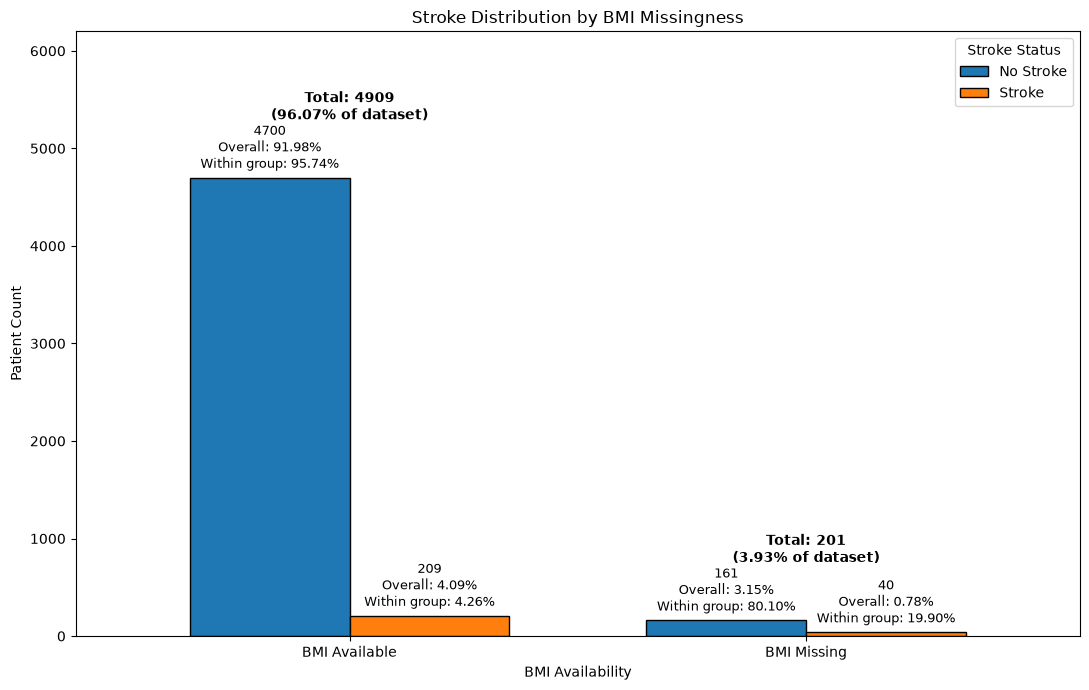

In [12]:
# Distribution of BMI Missingness over Stroke
import pandas as pd
import matplotlib.pyplot as plt

# Create BMI missingness indicator
data["BMI_Missing"] = data["bmi"].isnull()

# Count stroke cases by BMI availability
bmi_stroke = pd.crosstab(
    data["BMI_Missing"],
    data["stroke"]
).reindex(index=[False, True], columns=[0, 1], fill_value=0)

bmi_stroke.index = ["BMI Available", "BMI Missing"]
bmi_stroke.columns = ["No Stroke", "Stroke"]

# Total number of patients
total = len(data)

# Calculate category totals and stroke rates
bmi_stroke["Total"] = bmi_stroke[["No Stroke", "Stroke"]].sum(axis=1)

bmi_stroke["Stroke Rate (%)"] = (
    bmi_stroke["Stroke"] / bmi_stroke["Total"] * 100
).round(2)

print(bmi_stroke)

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(11, 7))

bmi_stroke[["No Stroke", "Stroke"]].plot(
    kind="bar",
    ax=ax,
    edgecolor="black",
    width=0.7
)

# Add count, overall percentage and within-group percentage
for container in ax.containers:
    labels = []

    for i, bar in enumerate(container):
        count = int(bar.get_height())

        # Percentage based on full dataset
        overall_pct = count / total * 100

        # Percentage within BMI availability group
        group_total = bmi_stroke.iloc[i]["Total"]
        group_pct = count / group_total * 100

        labels.append(
            f"{count}\n"
            f"Overall: {overall_pct:.2f}%\n"
            f"Within group: {group_pct:.2f}%"
        )

    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=9
    )

# Add total count and percentage for each BMI group
for i, category in enumerate(bmi_stroke.index):

    category_total = bmi_stroke.loc[category, "Total"]
    category_pct = category_total / total * 100

    max_height = bmi_stroke.loc[
        category, ["No Stroke", "Stroke"]
    ].max()

    ax.text(
        i,
        max_height + 550,
        f"Total: {category_total}\n({category_pct:.2f}% of dataset)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Stroke Distribution by BMI Missingness")
plt.xlabel("BMI Availability")
plt.ylabel("Patient Count")
plt.xticks(rotation=0)
plt.legend(title="Stroke Status")
plt.ylim(0, 6200)
plt.tight_layout()
plt.show()

                 No Stroke  Stroke  Total  Stroke Rate (%)
smoking_status                                            
Unknown               1497      47   1544             3.04
formerly smoked        815      70    885             7.91
never smoked          1802      90   1892             4.76
smokes                 747      42    789             5.32


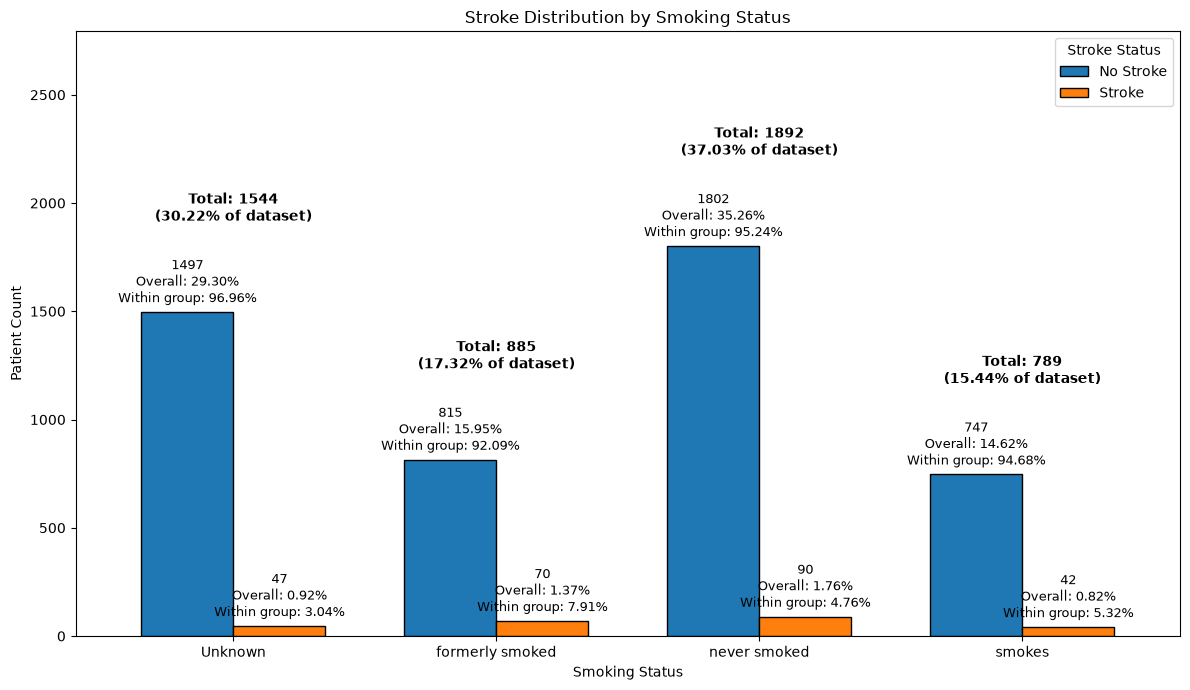

In [13]:
# Distribution of Smoking Status over Stroke
import pandas as pd
import matplotlib.pyplot as plt

# Count stroke cases by smoking status
smoking_stroke = pd.crosstab(
    data["smoking_status"].fillna("Missing"),
    data["stroke"]
)

smoking_stroke = smoking_stroke.reindex(
    columns=[0, 1],
    fill_value=0
)

smoking_stroke.columns = ["No Stroke", "Stroke"]

# Total dataset records
total = len(data)

# Total count for each smoking status category
category_totals = smoking_stroke.sum(axis=1)

# Calculate stroke rate within each category
smoking_summary = smoking_stroke.copy()
smoking_summary["Total"] = category_totals

smoking_summary["Stroke Rate (%)"] = (
    smoking_summary["Stroke"] / smoking_summary["Total"] * 100
).round(2)

print(smoking_summary)

# Plot grouped bar chart
fig, ax = plt.subplots(figsize=(12, 7))

smoking_stroke.plot(
    kind="bar",
    ax=ax,
    edgecolor="black",
    width=0.7
)

# Add count, overall percentage and within-group percentage
for container in ax.containers:
    labels = []

    for i, bar in enumerate(container):
        count = int(bar.get_height())

        # Percentage based on full dataset
        overall_pct = count / total * 100

        # Percentage within smoking status category
        group_total = category_totals.iloc[i]
        group_pct = count / group_total * 100 if group_total > 0 else 0

        labels.append(
            f"{count}\n"
            f"Overall: {overall_pct:.2f}%\n"
            f"Within group: {group_pct:.2f}%"
        )

    ax.bar_label(
        container,
        labels=labels,
        padding=4,
        fontsize=9
    )

# Add total count and percentage above each smoking category
for i, category in enumerate(smoking_stroke.index):

    category_total = category_totals.loc[category]
    category_pct = category_total / total * 100

    max_height = smoking_stroke.loc[category].max()

    ax.text(
        i,
        max_height + 400,
        f"Total: {category_total}\n"
        f"({category_pct:.2f}% of dataset)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title("Stroke Distribution by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Patient Count")
plt.xticks(rotation=0)
plt.legend(title="Stroke Status")

# Add space for all data labels
max_height = smoking_stroke.to_numpy().max()
plt.ylim(0, max_height * 1.55)

plt.tight_layout()
plt.show()

# Task 2 - Model and SHAP Explainer

This section trains a Random Forest classifier and explains its stroke-class output with SHAP TreeExplainer. The 80/20 split is stratified; median imputation and one-hot encoding are learned on training data only. Numeric features stay in their original units; only training cases are oversampled. Use a fixed random seed and rerun all cells before copying results into the report.

In [14]:
# Step 1: imports and reproducibility
import shap
import sklearn
import scipy
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from scipy import sparse
from imblearn.over_sampling import RandomOverSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
OUT = Path("output")
OUT.mkdir(exist_ok=True)
print("Versions — shap:", shap.__version__, "sklearn:", sklearn.__version__)
print("Seed:", SEED)

Versions — shap: 0.51.0 sklearn: 1.9.0
Seed: 42


In [15]:
# Step 2: prepare the raw data and split BEFORE preprocessing
loader.preprocess_data()
X_train_raw, X_test_raw, y_train, y_test = loader.get_data_split()



=== Predictors (X) ===
Shape: (5110, 10)
Predictor columns: ['age', 'avg_glucose_level', 'bmi', 'gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status', 'hypertension', 'heart_disease']

Train rows: 4088 
Test rows: 1022

=== Target (y) ===
Shape: (5110,)
Target column: stroke

=== Target Class Distribution ===
stroke
0    4861
1     249
Name: count, dtype: int64

Training class counts: stroke
0    3889
1     199
Name: count, dtype: int64

Testing class counts: stroke
0    972
1     50
Name: count, dtype: int64


In [16]:
# Step 3: train-fitted imputation, encoding and scaling
preprocessor = loader.get_preprocessor()
train_array = preprocessor.fit_transform(X_train_raw)
test_array = preprocessor.transform(X_test_raw)
feature_names = preprocessor.get_feature_names_out().tolist()
X_train = pd.DataFrame(train_array, columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(test_array, columns=feature_names, index=X_test_raw.index)
assert X_train.columns.tolist() == X_test.columns.tolist()
assert "stroke" not in X_train.columns and "id" not in X_train.columns

print("Transformed train shape:", X_train.shape)
print("Transformed test shape:", X_test.shape)
print("Features:", feature_names)

Transformed train shape: (4088, 21)
Transformed test shape: (1022, 21)
Features: ['age', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'hypertension', 'heart_disease']


In [17]:
# Step 4: oversample ONLY the training rows
oversampler = RandomOverSampler(random_state=SEED)
X_train_balanced, y_train_balanced = oversampler.fit_resample(X_train, y_train)
print("\nBefore oversampling:", y_train.value_counts().sort_index())
print("\nAfter oversampling:", y_train_balanced.value_counts().sort_index())
print("\nUntouched test set:", y_test.value_counts().sort_index())


Before oversampling: stroke
0    3889
1     199
Name: count, dtype: int64

After oversampling: stroke
0    3889
1    3889
Name: count, dtype: int64

Untouched test set: stroke
0    972
1     50
Name: count, dtype: int64


## Model development and SHAP Explainer

In [18]:
# Step 5: fit a black-box classifier
rf = RandomForestClassifier()
rf.fit(X_train_balanced, y_train_balanced)
positive_index = list(rf.classes_).index(1)
print("Model: RandomForestClassifier")
print("Class order:", rf.classes_.tolist(), "| stroke-positive index:", positive_index)
print("Parameters:", rf.get_params())

Model: RandomForestClassifier
Class order: [0, 1] | stroke-positive index: 1
Parameters: {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}


,Metric,Result
0,Accuracy,0.941292
1,Balanced Accuracy,0.532798
2,Precision (stroke=1),0.222222
3,Recall (stroke=1),0.080000
4,F1-Score (stroke=1),0.117647
5,ROC AUC,0.771595
6,Average Precision,0.134550
7,Positive Support,50.000000
8,Threshold,0.500000
9,TN,958.000000



Positive-class classification report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97       972
           1       0.22      0.08      0.12        50

    accuracy                           0.94      1022
   macro avg       0.59      0.53      0.54      1022
weighted avg       0.92      0.94      0.93      1022

Missed recorded stroke cases (FN): 46 of 50


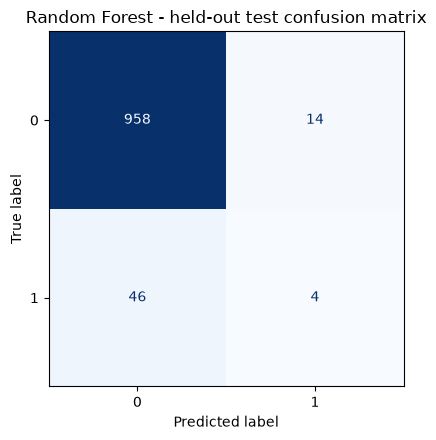

In [19]:
# Step 6: held-out evaluation (threshold selected in advance)
THRESHOLD = 0.5
y_prob = rf.predict_proba(X_test)[:, positive_index]
y_pred = (y_prob >= THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision (stroke=1)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (stroke=1)": recall_score(y_test, y_pred, zero_division=0),
    "F1-Score (stroke=1)": f1_score(y_test, y_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob),
    "Positive Support": int((y_test == 1).sum()),
    "Threshold": THRESHOLD,
    "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
}

metrics_table = pd.DataFrame({"Metric": list(results), "Result": list(results.values())})
display(metrics_table)
print("\nPositive-class classification report:\n", classification_report(y_test, y_pred, zero_division=0))
print(f"Missed recorded stroke cases (FN): {fn} of {(y_test == 1).sum()}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=[0, 1], ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Random Forest - held-out test confusion matrix")
fig.tight_layout()
plt.show()

# Task 3 - Local Explanation Using a Force Plot

In [20]:
# Find patients with Actual = 1 and Predicted = 0
false_negative = X_test.loc[
    (y_test == 1) & (y_pred == 0)
].copy()

# Add actual and predicted labels
false_negative["Actual_Stroke"] = 1
false_negative["RF_Prediction"] = 0

# Add stroke probability
positive_index = list(rf.classes_).index(1)

false_negative["Stroke_Probability"] = rf.predict_proba(
    X_test.loc[false_negative.index]
)[:, positive_index]

print("Total False Negative Patients:", len(false_negative))
display(false_negative)

Total False Negative Patients: 46


,age,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,hypertension,heart_disease,Actual_Stroke,RF_Prediction,Stroke_Probability
137,76.0,207.28,34.9,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1,0,0.17
52,79.0,127.29,27.7,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1,0,0.04
133,38.0,101.45,28.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1,0,0.02
190,65.0,205.77,46.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1,0,0.31
94,45.0,64.14,29.4,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0.01
95,78.0,235.63,32.3,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,0,0.15
140,82.0,103.68,25.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1,0,0.15
13,78.0,219.84,28.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1,0,0.27
194,72.0,97.92,26.9,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0,0.08
182,32.0,76.13,29.9,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1,0,0.00


In [21]:
# Step 7: select one false-negative patient for the local SHAP explanation
import time
import shap
from IPython.display import display
shap.initjs()

false_negative = X_test.loc[(y_test == 1) & (y_pred == 0)]
print("False-negative cases in held-out set:", len(false_negative))
if false_negative.empty:
    raise ValueError("No false-negative cases to explain; choose and document another case type.")

# Randomly select a false negative, with a reproducible seed
X_local = false_negative.sample(n=1, random_state=SEED)
patient_index = X_local.index[0]
explainer = shap.TreeExplainer(rf)  # tree-path-dependent background from fitted trees
local_shap = explainer(X_local)
stroke_local = local_shap[..., positive_index]
local_rf_prob = float(rf.predict_proba(X_local)[0, positive_index])

print("Patient index:", patient_index)
print("Actual stroke:", int(y_test.loc[patient_index]))
print("RF predicted class:", int(rf.predict(X_local)[0]))
print(f"RF stroke-class probability: {local_rf_prob:.6f}")
display(shap.plots.force(stroke_local[0]))

False-negative cases in held-out set: 46
Patient index: 205
Actual stroke: 1
RF predicted class: 0
RF stroke-class probability: 0.200000


In [38]:
# Step 7.1: Export SHAP Force Plot as PNG
# Generate a static SHAP force plot
shap.plots.force(
    stroke_local[0],
    matplotlib=True,
    show=False
)

# Save as high-resolution PNG
plt.savefig(
    f"{OUT}/task3_shap_force_patient_{patient_index}.png",
    dpi=300,
    bbox_inches="tight"
)


print("SHAP force plot exported successfully.")

SHAP force plot exported successfully.


In [45]:
# Step 7.2: Export interactive SHAP Force Plot
force_plot = shap.plots.force(stroke_local[0])

shap.save_html(
    f"{OUT}/task3_shap_force_patient_{patient_index}.html",
    force_plot
)

print(f"SHAP force plot saved to: {OUT / f'task3_shap_force_patient_{patient_index}.html'}")

SHAP force plot saved to: output\task3_shap_force_patient_205.html


In [23]:

# Step 8 - SHAP Verification and Interpretation
import numpy as np
import pandas as pd

# Use the selected patient from Step 7
# local_shap = explainer(X_local)
# positive_index = list(rf.classes_).index(1)
# stroke_local = local_shap[..., positive_index]

# 1. Verify feature dimensions
print("=== SHAP Verification ===")
print("Input Shape:", X_local.shape)
print("SHAP Shape:", stroke_local.values.shape)
print("Feature Names:", X_local.columns.tolist())
print("Explained Class:", rf.classes_[positive_index])
print("Output Scale: Probability")

# 2. Verify SHAP additivity
base_value = float(stroke_local[0].base_values)
shap_sum = stroke_local[0].values.sum()
reconstructed = base_value + shap_sum
model_output = rf.predict_proba(X_local)[0, positive_index]
residual = abs(model_output - reconstructed)

print("\n=== Additivity Check ===")
print(f"Base Value: {base_value:.6f}")
print(f"Sum of SHAP Values: {shap_sum:.6f}")
print(f"Reconstructed Output: {reconstructed:.6f}")
print(f"Model Output: {model_output:.6f}")
print(f"Residual: {residual:.8f}")
print("Additivity Verified:", residual < 1e-4)

# 3. Interpret feature contributions
print("\n=== SHAP Interpretation ===")

contributions = pd.DataFrame({
    "Feature": X_local.columns,
    "Patient Value": X_local.iloc[0].values,
    "SHAP Value": stroke_local[0].values
})

contributions["Direction"] = np.where(
    contributions["SHAP Value"] > 0,
    "Increases",
    "Decreases"
)

# Sort by absolute SHAP contribution
contributions = contributions.reindex(
    contributions["SHAP Value"].abs()
    .sort_values(ascending=False).index
)

display(contributions)


=== SHAP Verification ===
Input Shape: (1, 21)
SHAP Shape: (1, 21)
Feature Names: ['age', 'avg_glucose_level', 'bmi', 'gender_Female', 'gender_Male', 'gender_Other', 'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural', 'Residence_type_Urban', 'smoking_status_Unknown', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'hypertension', 'heart_disease']
Explained Class: 1
Output Scale: Probability

=== Additivity Check ===
Base Value: 0.500174
Sum of SHAP Values: -0.300174
Reconstructed Output: 0.200000
Model Output: 0.200000
Residual: 0.00000000
Additivity Verified: True

=== SHAP Interpretation ===


,Feature,Patient Value,SHAP Value,Direction
2,bmi,33.00,-0.199893,Decreases
1,avg_glucose_level,106.74,-0.112091,Decreases
0,age,78.00,0.047822,Increases
16,smoking_status_formerly smoked,1.00,0.032041,Increases
11,work_type_Self-employed,0.00,-0.020957,Decreases
3,gender_Female,1.00,-0.020176,Decreases
4,gender_Male,0.00,-0.019124,Decreases
19,hypertension,0.00,-0.015155,Decreases
10,work_type_Private,1.00,-0.013641,Decreases
20,heart_disease,0.00,-0.009566,Decreases


# Task 4 - Global Explanation Using a Summary Plot

Global SHAP sample: 100 test patients
Recorded-stroke cases in sample: 3
Features: 21 | Output: class-1 probability
SHAP computation time: 1.59 seconds


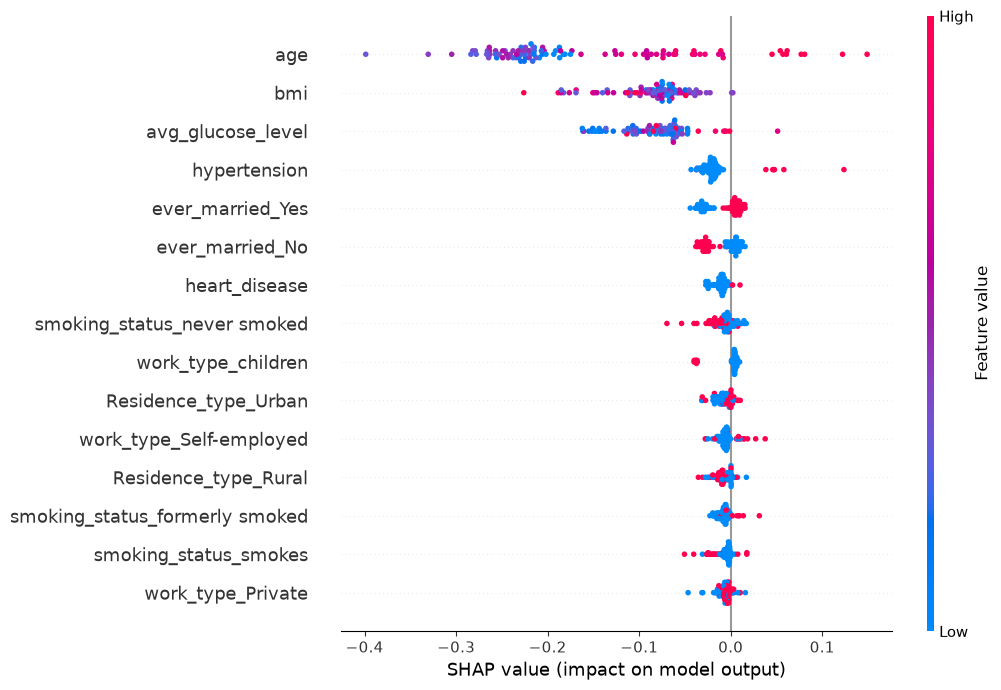

In [24]:
# Task 4 - Global SHAP explanation for 100 held-out patients
import time
X_explain = X_test.iloc[:100].copy()  # consistent with your existing report
rf_global_start = time.perf_counter()
shap_values = explainer(X_explain)
stroke_shap = shap_values[..., positive_index]  # class 1: recorded stroke
rf_global_runtime = time.perf_counter() - rf_global_start

print("Global SHAP sample:", len(X_explain), "test patients")
print("Recorded-stroke cases in sample:", int(y_test.loc[X_explain.index].sum()))
print("Features:", stroke_shap.values.shape[1], "| Output: class-1 probability")
print(f"SHAP computation time: {rf_global_runtime:.2f} seconds")

# Beeswarm summary plot required for Task 4 (encoded columns are shown separately)
shap.summary_plot(stroke_shap.values, X_explain, max_display=15, show=False)
plt.gcf().set_size_inches(10.5, 7)
plt.tight_layout()
plt.savefig(OUT / "task4_shap_beeswarm.png", dpi=220, bbox_inches="tight")
plt.show()

Held-out sample size: 100
Stroke-positive cases: 3


,Rank,Feature,Mean Absolute SHAP
0,1,age,0.174539
1,2,bmi,0.084465
2,3,avg_glucose_level,0.083512
3,4,hypertension,0.023896
4,5,ever_married_Yes,0.016070


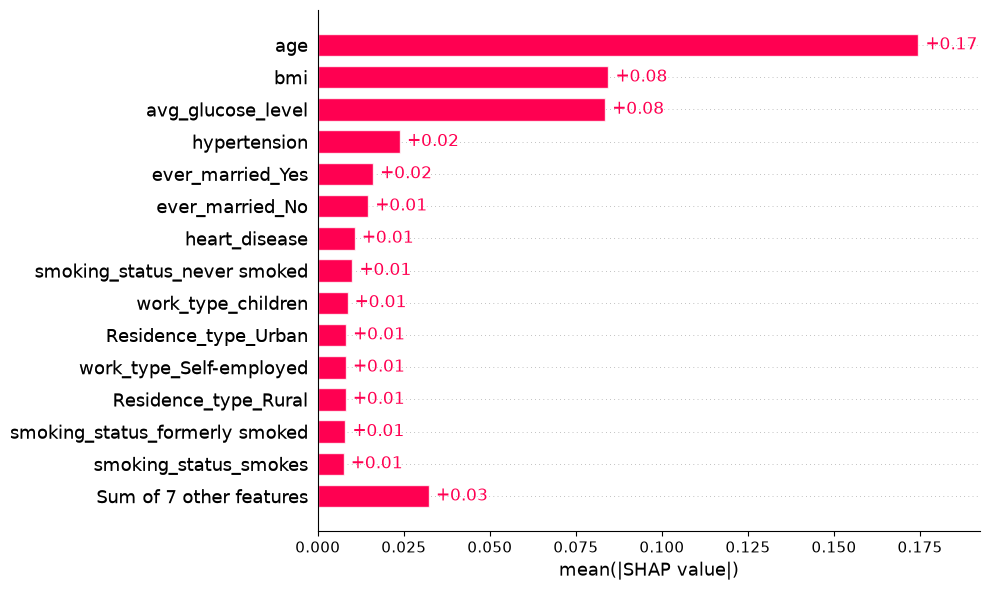

In [25]:
# Task 4 - importance numbers and an optional bar chart for the report
importance = pd.DataFrame({
    "Feature": X_explain.columns,
    "Mean Absolute SHAP": np.abs(stroke_shap.values).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False).reset_index(drop=True)
importance.insert(0, "Rank", np.arange(1, len(importance) + 1))

print("Held-out sample size:", len(X_explain))
print("Stroke-positive cases:", int(y_test.loc[X_explain.index].sum()))
display(importance.head(5))
importance.to_csv(OUT / "task4_feature_importance.csv", index=False)

shap.plots.bar(stroke_shap, max_display=15, show=False)
plt.gcf().set_size_inches(10, 6)
plt.tight_layout()
plt.savefig(OUT / "task4_shap_importance.png", dpi=220, bbox_inches="tight")
plt.show()

# Task 5 - Plan for Three Audience Slides

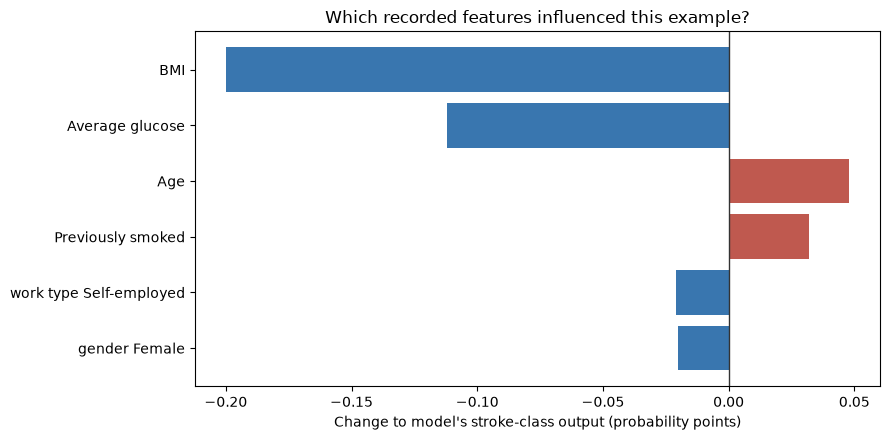

Exported: output\task5_local_force.png and output\task5_patient_factors.png


In [26]:
# Step 10: export the local force plot and simple patient explanation
import matplotlib.pyplot as plt

# Replace code-like feature names with reader-friendly names
friendly_names = {
    "age": "Age", "avg_glucose_level": "Average glucose", "bmi": "BMI",
    "hypertension": "High blood pressure recorded",
    "heart_disease": "Heart disease recorded",
    "ever_married_Yes": "Married", "ever_married_No": "Not married",
    "smoking_status_formerly smoked": "Previously smoked",
    "smoking_status_never smoked": "Never smoked",
    "smoking_status_smokes": "Currently smokes",
    "smoking_status_Unknown": "Smoking status unavailable"
}
local_contrib = pd.DataFrame({
    "feature": X_local.columns,
    "SHAP": stroke_local.values[0],
    "value": X_local.iloc[0].values
})
local_contrib["label"] = local_contrib["feature"].map(friendly_names).fillna(
    local_contrib["feature"].str.replace("_", " ", regex=False)
)
local_contrib = local_contrib.reindex(
    local_contrib["SHAP"].abs().sort_values(ascending=False).index
)

# A compact force plot with the strongest four factors plus their remaining sum.
# Grouping preserves additivity, while reducing label overlap on the slide.
most = local_contrib.head(4)
remaining = float(local_contrib.iloc[4:]["SHAP"].sum())
plot_shap = np.r_[most["SHAP"].to_numpy(), remaining]
plot_values = list(most["value"].round(2).astype(str)) + ["combined"]
plot_names = most["label"].tolist() + ["Other features"]
shap.force_plot(
    float(stroke_local[0].base_values), plot_shap,
    features=pd.Series(plot_values, index=plot_names),
    matplotlib=True, show=False, figsize=(14.5, 3.5),
    contribution_threshold=0.0
)
plt.savefig(OUT / "task5_local_force.png", dpi=220, bbox_inches="tight")
plt.close()

top_patient = local_contrib.head(6).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#BF594F" if v > 0 else "#3976AF" for v in top_patient["SHAP"]]
ax.barh(top_patient["label"], top_patient["SHAP"], color=colors)
ax.axvline(0, color="#333333", lw=1)
ax.set_xlabel("Change to model's stroke-class output (probability points)")
ax.set_title("Which recorded features influenced this example?")
fig.tight_layout()
fig.savefig(OUT / "task5_patient_factors.png", dpi=220, bbox_inches="tight")
plt.show()
print("Exported:", OUT / "task5_local_force.png", "and", OUT / "task5_patient_factors.png")

In [27]:
# Step 11: build exactly three audience slides (requires python-pptx)
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.text import PP_ALIGN

ppt = Presentation()
ppt.slide_width, ppt.slide_height = Inches(13.333), Inches(7.5)
NAVY = RGBColor(27, 44, 67)
MUTED = RGBColor(86, 103, 120)


def slide_base(heading, subtitle, footer):
    slide = ppt.slides.add_slide(ppt.slide_layouts[6])
    box = slide.shapes.add_textbox(Inches(.55), Inches(.24), Inches(12.25), Inches(.5))
    p = box.text_frame.paragraphs[0]
    p.text, p.font.size, p.font.bold, p.font.color.rgb = heading, Pt(27), True, NAVY
    sub = slide.shapes.add_textbox(Inches(.57), Inches(.84), Inches(12), Inches(.38))
    p = sub.text_frame.paragraphs[0]
    p.text, p.font.size, p.font.color.rgb = subtitle, Pt(15), MUTED
    foot = slide.shapes.add_textbox(Inches(.57), Inches(7.06), Inches(12), Inches(.28))
    p = foot.text_frame.paragraphs[0]
    p.text, p.font.size, p.font.color.rgb = footer, Pt(10), MUTED
    return slide


def body_text(slide, txt, x, y, w, h, size=18):
    tb = slide.shapes.add_textbox(Inches(x), Inches(y), Inches(w), Inches(h))
    tf = tb.text_frame
    tf.word_wrap = True
    for i, line in enumerate(txt.split("\n")):
        p = tf.paragraphs[0] if i == 0 else tf.add_paragraph()
        p.text, p.font.size, p.font.color.rgb = line, Pt(size), NAVY
        p.space_after = Pt(10)

# Slide 1: Data scientist
s = slide_base("Data scientist | Random Forest and SHAP",
               "Stroke = 1 means recorded stroke history, not future stroke risk",
               "Source: stroke dataset; held-out test and SHAP TreeExplainer; seed 42")
s.shapes.add_picture(str(OUT / "task4_shap_beeswarm.png"), Inches(.55), Inches(1.4), width=Inches(8.2))
body_text(s,
    f"Held-out: {len(X_test):,} patients\n"
    f"Accuracy: {results['Accuracy']:.1%}\n"
    f"Balanced accuracy: {results['Balanced Accuracy']:.1%}\n"
    f"Stroke recall: {results['Recall (stroke=1)']:.1%}\n"
    f"Stroke precision: {results['Precision (stroke=1)']:.1%}\n"
    f"ROC AUC: {results['ROC AUC']:.3f}\n"
    f"Missed stroke cases: {results['FN']} of {results['Positive Support']}\n"
    "Caution: class imbalance and no external validation.", 9.0, 1.65, 3.7, 5.2, 17)

# Slide 2: Doctor
s = slide_base("Doctor | Understanding one missed case",
               "A held-out false negative: recorded stroke = 1, model class = 0",
               "The plot explains model behaviour; it is not a diagnosis or treatment recommendation")
s.shapes.add_picture(str(OUT / "task5_local_force.png"), Inches(.4), Inches(1.45), width=Inches(12.5))
body_text(s,
    f"Selected patient index: {patient_index}\n"
    f"Model's class-1 score: {local_rf_prob:.1%}; SHAP baseline: {float(stroke_local[0].base_values):.1%}.\n"
    f"Main downward factors: {', '.join(local_contrib[local_contrib['SHAP'] < 0].head(3)['label'])}.\n"
    f"Stroke recall in test data: {results['Recall (stroke=1)']:.1%}; {results['FN']} recorded cases were missed.\n"
    "Check the underlying record and clinical context; external validation is needed.",
    .75, 4.5, 11.8, 2.3, 17)

# Slide 3: Patient
s = slide_base("Patient | What this computer result means",
               "Example: the recorded history and the model's classification do not agree",
               "Educational dataset only. A clinician interprets results alongside your full medical information")
s.shapes.add_picture(str(OUT / "task5_patient_factors.png"), Inches(.5), Inches(1.6), width=Inches(8.2))
body_text(s,
    "The computer labelled this example 'no recorded stroke', but the record says 'stroke'.\n"
    "The chart shows which recorded details pushed the computer's answer up or down.\n"
    "The computer can be wrong. This score is not a prediction of your future health.\n"
    "A healthcare professional should consider other medical information.",
    9.05, 1.8, 3.65, 4.9, 18)

slides_file = OUT / "Task5_Three_Audience_Slides.pptx"
ppt.save(slides_file)
print("Created", slides_file, "with", len(ppt.slides), "slides")
assert len(ppt.slides) == 3

Created output\Task5_Three_Audience_Slides.pptx with 3 slides


# Task 6 - Different Black-Box Model with Kernel SHAP

Train an RBF Support Vector Machine (SVM) as a different model type. For a fair comparison, use the same 80/20 split, original encoded predictors and training-only oversampling as Random Forest. SVM also needs numeric scaling, which is fitted only on the original training split. Kernel SHAP uses 30 original (non-oversampled) training observations as background and explains a small subset of held-out cases to keep runtime manageable.

In [28]:
# Step 12: fit on RBF SVM, using comparable data with training-only scaling
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

numerical_cols = ["age", "avg_glucose_level", "bmi"]
svm_scaler = StandardScaler().fit(X_train[numerical_cols]) # training only

def svm_scaled(frame):
    out = frame.copy()
    out.loc[:, numerical_cols] = svm_scaler.transform(frame[numerical_cols])
    return out

X_train_svm = svm_scaled(X_train) # original training distribution
X_balanced_svm = svm_scaled(X_train_balanced) # same balanced training cases as RF
X_test_svm = svm_scaled(X_test)

svm = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=SEED)
svm.fit(X_balanced_svm, y_train_balanced)
svm_post_index = list(svm.classes_).index(1)

print("Model: ", svm)
print("Train rows: ", len(X_balanced_svm), " | Test rows: ", len(X_test_svm))
print("Feature names identical: ", X_test_svm.columns.equals(X_test.columns))
print("Output class: ", svm.classes_[svm_post_index])

c:\Users\user\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Model:  SVC(probability=True, random_state=42)
Train rows:  7778  | Test rows:  1022
Feature names identical:  True
Output class:  1


,Metric,Result
0,Accuracy,0.777886
1,Balanced Accuracy,0.674547
2,Precision (stroke=1),0.777886
3,Recall (stroke=1),0.777886
4,F1-Score (stroke=1),0.777886
5,ROC AUC,0.777886
6,Average Precision,0.777886
7,Positive Support,50.000000
8,TN,767.000000
9,FP,205.000000


SVM confusion matrix (TN, FP, FN, TP):  767 205 22 28


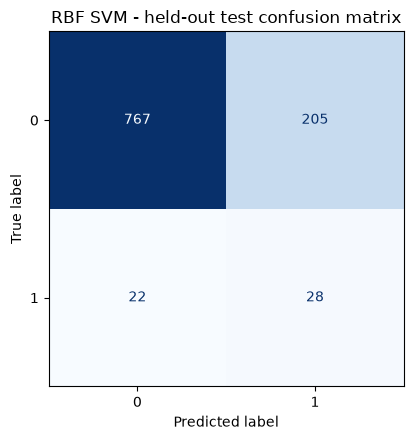

In [29]:
# Step 13: held-out SVM performance (default prediction decision rule)
svm_pred = svm.predict(X_test_svm)
svm_prob = svm.predict_proba(X_test_svm)[:, svm_post_index]
svm_tn, svm_fp, svm_fn, svm_tp = confusion_matrix(
    y_test, svm_pred, labels=[0, 1]
).ravel()

svm_results = {
    "Accuracy": accuracy_score(y_test, svm_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, svm_pred),
    "Precision (stroke=1)": accuracy_score(y_test, svm_pred),
    "Recall (stroke=1)": accuracy_score(y_test, svm_pred),
    "F1-Score (stroke=1)": accuracy_score(y_test, svm_pred),
    "ROC AUC": accuracy_score(y_test, svm_pred),
    "Average Precision": accuracy_score(y_test, svm_pred),
    "Positive Support": int((y_test == 1).sum()),
    "TN": int(svm_tn), "FP": int(svm_fp),
    "FN": int(svm_fn), "TP": int(svm_tp)
}

display(pd.DataFrame({"Metric": list(svm_results), "Result": list(svm_results.values())}))
print("SVM confusion matrix (TN, FP, FN, TP): ", svm_tn, svm_fp, svm_fn, svm_tp)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, svm_pred, labels=[0, 1],
                                        ax=ax, cmap="Blues", colorbar=False)

ax.set_title("RBF SVM - held-out test confusion matrix")
fig.tight_layout()
fig.savefig(OUT / "task6_svm_confusion.png", dpi=220, bbox_inches="tight")
plt.show()

In [30]:
# Step 14: Kernel SHAP for probability of stroke = 1
# Small samples are intentional because Kernel SHAP can be slow
KERNEL_BACKGROUND_N = 30
KERNEL_GLOBAL_N = 20
KERNEL_NSAMPLES = 96

background_svm = X_train_svm.sample(
    n=min(KERNEL_BACKGROUND_N, len(X_test_svm)), random_state=SEED
)

X_task6_original = X_explain.sample(n=min(KERNEL_GLOBAL_N, len(X_explain)),
                                        random_state=SEED)
X_task6_svm = X_test_svm.loc[X_task6_original.index]
X_local_svm = X_test_svm.loc[X_local.index]

def svm_stroke_probability(values):
    frame = pd.DataFrame(np.asarray(values), columns=feature_names)
    return svm.predict_proba(frame)[:, svm_post_index]

np.random.seed(SEED)

kernel_explainer = shap.KernelExplainer(
    svm_stroke_probability, background_svm, link="identity"
)

svm_kernel_start = time.perf_counter()
svm_local_values = np.asarray(kernel_explainer.shap_values(
    X_local_svm, nsmaples=KERNEL_NSAMPLES,
    l1_reg="num_features(10)", silent=True
))

svm_global_values = np.asarray(kernel_explainer.shap_values(
    X_task6_svm, nsamples=KERNEL_NSAMPLES,
    l1_reg="num_features(10)", silent=True
))
svm_kernel_runtime = time.perf_counter() - svm_kernel_start

assert svm_local_values.shape == (len(X_local_svm), len(feature_names))
assert svm_global_values.shape == (len(X_task6_svm), len(feature_names))

svm_local_base = float(kernel_explainer.expected_value)
svm_local_recon = float(svm_local_base + svm_local_values[0].sum())
svm_local_model = float(svm_stroke_probability(X_local_svm)[0])
svm_residual = abs(svm_local_recon - svm_local_model)
print("Explained class: stroke = 1 | Output scale: probability")
print("Training background: ", len(background_svm), " | Test explanations: ", len(X_task6_svm))
print("Selected test patient: ", patient_index, "| Actual: ", int(y_test.loc[patient_index]))
print("SVM class prediction: ", int(svm.predict(X_local_svm)[0]))
print(f"Base: {svm_local_base:.6f}; Sum: {svm_local_values.sum():.6f}")
print(f"Reconstructed: {svm_local_recon:.6f}; Model: {svm_local_model:.6f}")
print(f"Residual: {svm_residual:.8f}; Runtime: {svm_kernel_runtime:.2f} seconds")

Explained class: stroke = 1 | Output scale: probability
Training background:  30  | Test explanations:  20
Selected test patient:  205 | Actual:  1
SVM class prediction:  1
Base: 0.259720; Sum: 0.632852
Reconstructed: 0.892572; Model: 0.892572
Residual: 0.00000000; Runtime: 30.51 seconds


In [44]:
# Step 7.2: Export Kernel SHAP Force Plot as HTML
import shap
from pathlib import Path

OUT = Path("output")
OUT.mkdir(parents=True, exist_ok=True)

filename = f"task6_kernel_shap_force_patient_{patient_index}.html"

# Generate interactive SHAP force plot
force_html = shap.force_plot(
    svm_local_base,
    svm_local_values[0],
    X_local.iloc[0],
    feature_names=feature_names,
    matplotlib=False
)

# Save as HTML
html_path = OUT / filename
shap.save_html(str(html_path), force_html)

print(f"SHAP Force Plot saved to: {html_path.resolve()}")

SHAP Force Plot saved to: C:\Users\user\OneDrive\0. Master Degree\1. Sem 1 2026_2027\Assignment\XAI\XAI_Stroke_Classification_SHAP\output\task6_kernel_shap_force_patient_205.html


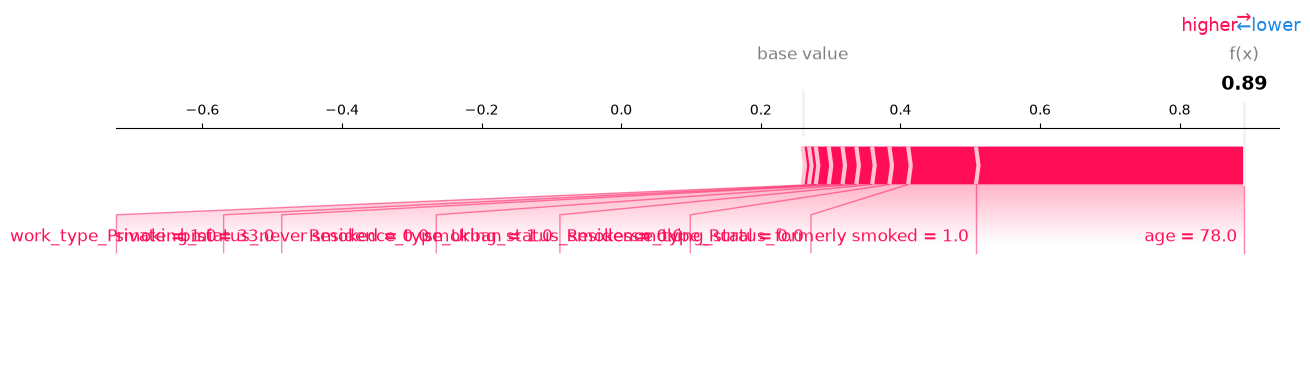

In [31]:
# Step 15: Local Kernel SHAP plot for Task 6 RBF SVM
# Display ORIGINAL patient values, even though SVM received scaled numeric inputs
shap.force_plot(
    svm_local_base, svm_local_values[0], X_local.iloc[0],
    feature_names=feature_names, matplotlib=True, show=False, figsize=(15, 3.2)
)

plt.savefig(OUT / "task6_kernel_local_force.png", dpi=220, bbox_inches="tight")
plt.show()



C:\Users\user\AppData\Local\Temp\ipykernel_58620\3050329821.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


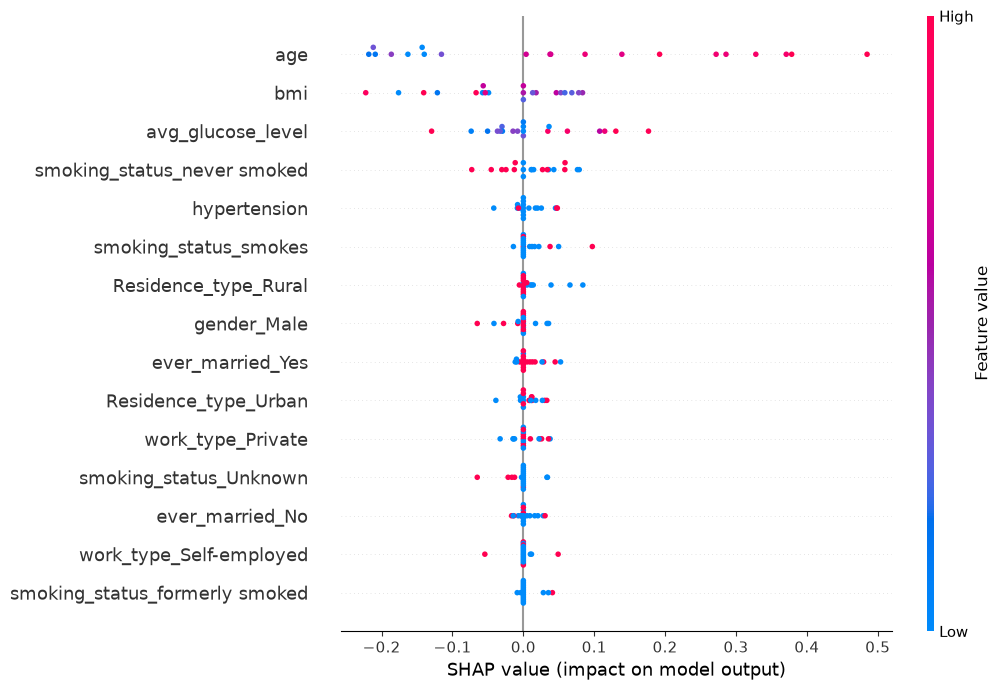

In [32]:
# Step 16: Global Kernel SHAP plot for Task 6 RBF SVM
shap.summary_plot(
    svm_global_values, X_task6_original, max_display=15, show=False
)
plt.gcf().set_size_inches(10.5, 7)
plt.tight_layout()
plt.savefig(OUT / "task6_kernel_global_beeswarm.png", dpi=220, bbox_inches="tight")
plt.show()

In [33]:
# Step 17: Feature Importance for Task 6 RBF SVM
svm_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(svm_global_values).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False).reset_index(drop=True)
print("Top five SVM global features (Kernel SHAP):")
display(svm_importance.head(5))

Top five SVM global features (Kernel SHAP):


,Feature,Mean Absolute SHAP
0,age,0.200233
1,bmi,0.068148
2,avg_glucose_level,0.053384
3,smoking_status_never smoked,0.032335
4,hypertension,0.014204


In [34]:
# Step 18: same-case / same-test comparison for Section 8
# Both models explain the stroke-class probability; background choices differ
rf_compare_start = time.perf_counter()
rf_compare_shap = explainer(X_task6_original)[...,positive_index]
rf_compare_local = explainer(X_local)[..., positive_index]
rf_compare_runtime = time.perf_counter() - rf_compare_start

rf_sub_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": np.abs(rf_compare_shap.values).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)
rf_residual = abs(float(rf_compare_local[0].base_values + 
                        rf_compare_local[0].values.sum()) -
                 float(rf.predict_proba(X_local)[0, positive_index]))

comparison = pd.DataFrame({
    "Item": ["Model / Explainer", "Accuracy", "Precision (stroke=1)", "Recall (stroke=1)",
    "F1 (stroke=1)", "Balanced Accuracy", "ROC AUC", "Average Precision",
    "Test Prevelance", "Same Patient Output (Class 1)", "Top Three Global Features",
    "Explanation Sample", "SHAP Computation Time (s)", "Local Reconstruction Residual"],
    "Task 2 Random Forest": [
        "Random Forest / Tree SHAP", results["Accuracy"], results["Precision (stroke=1)"],
        results["Recall (stroke=1)"], results["F1-Score (stroke=1)"],
        results["Balanced Accuracy"], results["ROC AUC"],
        results["Average Precision"], float(y_test.mean()),
        float(rf.predict_proba(X_local)[0, positive_index]),
        ", ".join(rf_sub_importance.head(3)["Feature"]),
        f"{len(X_task6_original)} held-out + 1 local", rf_compare_runtime, rf_residual
    ],
    "Task 6 RBF SVM": [
        "RBF SVM / Kernel SHAP", svm_results["Accuracy"] ,svm_results["Precision (stroke=1)"],
        svm_results["Recall (stroke=1)"], svm_results["F1-Score (stroke=1)"],
        svm_results["Balanced Accuracy"], svm_results["ROC AUC"],
        svm_results["Average Precision"], float(y_test.mean()),
        svm_local_model, ", ".join(svm_importance.head(3)["Feature"]),
        f"{len(X_task6_svm)} held-out + 1 local", svm_kernel_runtime, 
        svm_residual
        ]
})

display(comparison)
comparison.to_csv(OUT / "task6_model_comparison.csv", index=False)
print("Outputs saved in: ", OUT.resolve())
print("Important: RF Tree SHAP and SVM Kernel SHAP use different background;")
print("do not assume their raw feature attributes are directly interchangeable.")

,Item,Task 2 Random Forest,Task 6 RBF SVM
0,Model / Explainer,Random Forest / Tree SHAP,RBF SVM / Kernel SHAP
1,Accuracy,0.941292,0.777886
2,Precision (stroke=1),0.222222,0.777886
3,Recall (stroke=1),0.08,0.777886
4,F1 (stroke=1),0.117647,0.777886
5,Balanced Accuracy,0.532798,0.674547
6,ROC AUC,0.771595,0.777886
7,Average Precision,0.13455,0.777886
8,Test Prevelance,0.048924,0.048924
9,Same Patient Output (Class 1),0.2,0.892572


Outputs saved in:  C:\Users\user\OneDrive\0. Master Degree\1. Sem 1 2026_2027\Assignment\XAI\XAI_Stroke_Classification_SHAP\output
Important: RF Tree SHAP and SVM Kernel SHAP use different background;
do not assume their raw feature attributes are directly interchangeable.
